In [1]:
import numpy as np
import scipy.constants
import scipy.sparse
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import xarray as xr
import math
import geopandas as gpd
import pandas as pd
import os
import netCDF4 as nc
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# Used for suppressing C output
import os
import sys
from contextlib import contextmanager

# Save folder to a general directory
from pathlib import Path

# Add a folder for Matplotlib to store its setup/cache files there (increase plotting speed) 
matplotlib_cache = Path.cwd() / ".matplotlib_cache"
matplotlib_cache.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(matplotlib_cache))
#Note: currently not visible, likely bc its a hidden file

'/Users/aubreybrostedt/Projects/aubrey_cem/.matplotlib_cache'

In [3]:
max_angle,A,U = (45, 0.55, 0.6)

In [4]:

def calc_alongshore_transport_k(gravity=scipy.constants.g, n=1.0, rho_water=1050.0, gamma_b=0.78, ):
    return (
        5.3e-6
        # * 0.46
        * rho_water
        * gravity**1.5
        * (1 / (2 * n)) ** 1.2
        * (np.sqrt(gravity * gamma_b) / (2 * np.pi)) ** 0.2
    )

# Get_angles_xr description: Takes average latitude and longitude calculated in beach_w_to_gps.ipynb and computes bearing using bearing formula, then uses those values for the rose diagram
# It seems like all of this is for that red dotted line on the rose diagram that indicates shoreline position, is this true? And if so, is it really necessary that I reproduce this?
def get_angles_xr(ds):
    
    ''' Takes average latitude and longitude calculated in beahc_w_to_gps.ipynb and computes bearing using bearing formula
    \(\theta =\>\mathrm{atan2}\>(\sin \Delta \lambda \cdot \cos \phi _{2},\cos \phi _{1}\cdot \sin \phi _{2}-\sin \phi _{1}\cdot \cos \phi _{2}\cdot \cos \Delta \lambda )\)'''
    
    lat = np.radians(ds['mean_lat'])
    lon = np.radians(ds['mean_lon'])

    lat1 = lat.shift(site=1)
    lon1 = lon.shift(site=1)
    lat2 = lat.shift(site=-1)
    lon2 = lon.shift(site=-1)

    dlon = lon2 - lon1
    
    y = np.sin(dlon) * np.cos(lat2)
    x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)

    bearing = np.degrees(np.arctan2(y, x))
    bearing = (bearing + 360) % 360

    return bearing.fillna(0)


In [5]:
def calc_qs(dp, hs, tp, angles, k):
    '''Calculates Q_s using Ashton & Murray 2006B eq. (7). Negative sign makes positive Q_s
    correspond to rightward transport when facing offshore (here, roughly southbound).'''

    tp_da = tp['tp'] if isinstance(tp, xr.Dataset) else tp
    hs_da = hs['hs'] if isinstance(hs, xr.Dataset) else hs
    dp_da = dp['dp'] if isinstance(dp, xr.Dataset) else dp

    phi  = dp_da - 90
    thet = ((angles + 90) % 360) - 90
    angle_term = ((phi - thet + 180) % 360) - 180          # wrap to [-180, 180)
    angle_term = angle_term.where(np.abs(angle_term) <= 90) # NaN where offshore-directed
    angle_term = angle_term * (np.pi / 180)
    angle_term = angle_term.rename('angle term')

    cos_term = np.cos(angle_term)
    sin_term = np.sin(angle_term)
    qs = -k * (tp_da ** 0.2) * (hs_da ** 2.4) * (cos_term ** 1.2) * sin_term
    # qs = -k * (hs_da ** 2) * cos_term * sin_term # breaking wave formula
    return qs, angle_term



def energy_calc(dp,hs,tp,angles,k):
    tp_da = tp['tp'] if isinstance(tp,xr.Dataset) else tp
    hs_da = hs['hs'] if isinstance(hs,xr.Dataset) else hs
    dp_da = dp['dp'] if isinstance(dp,xr.Dataset) else dp

    phi = dp_da - 90
    theta = ((angles+90) % 360)- 90
    angle_term = ((phi - theta + 180) % 360) - 180
    angle_term = angle_term.where(np.abs(angle_term) <= 90) # Offshore-directed wave angles become NaN values
    angle_term  = angle_term * (np.pi/ 180)
    angle_term = angle_term.rename('angle term')
    E = -k * (tp_da ** 0.2) * (hs_da ** 2.4)
    E = E.where(angle_term.notnull()) # remove offshore wave angles from E

    return E, angle_term
    

In [6]:
dp = xr.open_dataset('/Users/aubreybrostedt/Downloads/dp_NorthCarolina.nc') # peak direction
hs = xr.open_dataset('/Users/aubreybrostedt/Downloads/hs_NorthCarolina.nc') # peak direction
tp = xr.open_dataset('/Users/aubreybrostedt/Downloads/tp_NorthCarolina.nc') # peak direction

dp0 = xr.open_dataset('/Users/aubreybrostedt/Downloads/dp0_NorthCarolina.nc') # peak direction
dp1 = xr.open_dataset('/Users/aubreybrostedt/Downloads/dp1_NorthCarolina.nc') # peak direction
dp2 = xr.open_dataset('/Users/aubreybrostedt/Downloads/dp2_NorthCarolina.nc') # peak direction
dp3 = xr.open_dataset('/Users/aubreybrostedt/Downloads/dp3_NorthCarolina.nc') # peak direction

hs0 = xr.open_dataset('/Users/aubreybrostedt/Downloads/phs0_NorthCarolina.nc') # wave height
hs1 = xr.open_dataset('/Users/aubreybrostedt/Downloads/phs1_NorthCarolina.nc') # wave height
hs2 = xr.open_dataset('/Users/aubreybrostedt/Downloads/phs2_NorthCarolina.nc') # wave height
hs3 = xr.open_dataset('/Users/aubreybrostedt/Downloads/phs3_NorthCarolina.nc') # wave height

tp0 = xr.open_dataset('/Users/aubreybrostedt/Downloads/ptp0_NorthCarolina.nc') # peak period
tp1 = xr.open_dataset('/Users/aubreybrostedt/Downloads/ptp1_NorthCarolina.nc') # peak period
tp2 = xr.open_dataset('/Users/aubreybrostedt/Downloads/ptp2_NorthCarolina.nc') # peak period
tp3 = xr.open_dataset('/Users/aubreybrostedt/Downloads/ptp3_NorthCarolina.nc') # peak period

In [7]:
k = calc_alongshore_transport_k()
angles = 60
num_sites = 9
qs, angle_term = calc_qs(dp,hs,tp,angles,k)
angle_term

<xarray.DataArray 'angle term' (time: 55843, site: 9)> Size: 2MB
array([[ 0.32850865,  0.2371039 , -0.03503016, ...,  0.9141998 ,
         0.69271964,  0.6424469 ],
       [        nan,         nan,  1.1490278 , ...,  1.5623286 ,
         1.0389109 ,  0.27825585],
       [-0.5302471 , -0.9208666 , -0.9179313 , ..., -0.667643  ,
        -0.9078905 , -0.35760847],
       ...,
       [-0.7213885 , -0.89373344, -0.88873917, ..., -0.96594024,
        -0.6153207 , -0.55290204],
       [-0.39839852, -0.4855928 , -0.630248  , ..., -0.3368542 ,
        -0.49863163, -0.49387524],
       [        nan,  1.3320684 ,  1.0705771 , ...,  0.70248914,
         0.843499  ,  0.84638375]], shape=(55843, 9), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 447kB 1871-01-01 1871-01-02 ... 2023-11-22
  * site     (site) <U4 144B '2964' '2963' '1670' '3124' ... '2776' '1517' '696'
    lat      (site) float64 72B 36.4 36.3 36.26 36.19 ... 34.81 34.12 33.38
    lon      (site) float64 72B -75.2 -75.4 -75.59 ... -75.81 -77.0 -78.38

In [8]:
wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = dp0.lat.values
transect_lons = dp0.lon.values

def get_nearest_indices(w_lats, w_lons, t_lats, t_lons):
    indices = []
    for lat, lon in zip(t_lats, t_lons):
        dist = np.sqrt((w_lats - lat)**2 + (w_lons - lon)**2)
        indices.append(np.argmin(dist))
    return np.array(indices)

mapping_idx = get_nearest_indices(wave_lats, wave_lons, transect_lats, transect_lons)

dp0_mapped = dp0.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
hs0_mapped = hs0.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
tp0_mapped = tp0.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)

#Data for partition 1
dp1_mapped = dp1.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)

hs1_mapped = hs1.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
tp1_mapped = tp1.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)

#Data for partition 2
dp2_mapped = dp2.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
hs2_mapped = hs2.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
tp2_mapped = tp2.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)

#Data for partition 3
dp3_mapped = dp3.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
hs3_mapped = hs3.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
tp3_mapped = tp3.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)

#Data for bulk partition
dp_mapped = dp.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
hs_mapped = hs.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)
tp_mapped = tp.isel(site=mapping_idx).assign_coords(
    site=dp0.site.values, 
    lat=("site", transect_lats), 
    lon=("site", transect_lons)
)

In [9]:
dp = {
    0: dp0_mapped,
    1: dp1_mapped,
    2: dp2_mapped,
    3: dp3_mapped,
    4: dp_mapped
}

hs = {
    0: hs0_mapped,
    1: hs1_mapped,
    2: hs2_mapped,
    3: hs3_mapped,
    4: hs_mapped
}

tp = {
    0: tp0_mapped,
    1: tp1_mapped,
    2: tp2_mapped,
    3: tp3_mapped,
    4: tp_mapped
}

for i in range(5):
    file_name = f'ncqs{i}_hourly_pertransect.nc'
    if os.path.exists(file_name):
        os.remove(file_name)
    
    dp_mapped = dp[i]
    hs_mapped = hs[i]
    tp_mapped = tp[i]
    total_time_len = len(dp_mapped.time)
    
    full_template = xr.Dataset(
        data_vars={
            "qs": (("time", "site"), np.zeros((total_time_len, num_sites), dtype='float32')),
            "angle_diff": (("time", "site"), np.zeros((total_time_len, num_sites), dtype='float32')),
            "lat": ("site", dp0.lat.values),
            "lon": ("site", dp0.lon.values)
        },
        coords={"time": dp_mapped.time, "site": dp_mapped.site}
    )
    
    full_template.to_netcdf(file_name) 
    
    k = calc_alongshore_transport_k()
    
    with nc.Dataset(file_name, 'a') as dst:
        step = 30000
        for j in range(0, total_time_len, step):
            end_idx = min(j + step, total_time_len)
            print(f"Writing indices: {j} to {end_idx}...")
            
            dp_slice = dp_mapped.isel(time=slice(j, end_idx))
            hs_slice = hs_mapped.isel(time=slice(j, end_idx))
            tp_slice = tp_mapped.isel(time=slice(j, end_idx))
            
            qs_slice,angle_slice = calc_qs(dp_slice, hs_slice, tp_slice, angles, k)
    
            dst['qs'][j:end_idx, :] = qs_slice.values
            dst['angle_diff'][j:end_idx, :] = angle_slice.values
    
    print(f"Saved as {file_name}")


Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncqs0_hourly_pertransect.nc
Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncqs1_hourly_pertransect.nc
Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncqs2_hourly_pertransect.nc
Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncqs3_hourly_pertransect.nc
Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncqs4_hourly_pertransect.nc


In [10]:
for i in range(5):
    file_name = f'ncE{i}_hourly_pertransect.nc'
    if os.path.exists(file_name):
        os.remove(file_name)
    
    dp_mapped = dp[i]
    hs_mapped = hs[i]
    tp_mapped = tp[i]
    total_time_len = len(dp_mapped.time)
    
    full_template = xr.Dataset(
        data_vars={
            "E": (("time", "site"), np.zeros((total_time_len, num_sites), dtype='float32')),
            "angle_diff": (("time", "site"), np.zeros((total_time_len, num_sites), dtype='float32')),
            "lat": ("site", dp0.lat.values),
            "lon": ("site", dp0.lon.values)
        },
        coords={"time": dp_mapped.time, "site": dp_mapped.site}
    )
    
    full_template.to_netcdf(file_name) 
    
    k = calc_alongshore_transport_k()
    
    with nc.Dataset(file_name, 'a') as dst:
        step = 30000
        for j in range(0, total_time_len, step):
            end_idx = min(j + step, total_time_len)
            print(f"Writing indices: {j} to {end_idx}...")
            
            dp_slice = dp_mapped.isel(time=slice(j, end_idx))
            hs_slice = hs_mapped.isel(time=slice(j, end_idx))
            tp_slice = tp_mapped.isel(time=slice(j, end_idx))
            
            E_slice,angle_slice = energy_calc(dp_slice, hs_slice, tp_slice, angles, k)
    
            dst['E'][j:end_idx, :] = E_slice.values
            dst['angle_diff'][j:end_idx, :] = angle_slice.values
    
    print(f"Saved as {file_name}")

Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncE0_hourly_pertransect.nc
Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncE1_hourly_pertransect.nc
Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncE2_hourly_pertransect.nc
Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncE3_hourly_pertransect.nc
Writing indices: 0 to 30000...
Writing indices: 30000 to 55843...
Saved as ncE4_hourly_pertransect.nc


In [11]:
ds = xr.open_dataset('./ncE0_hourly_pertransect.nc')
print(ds)

<xarray.Dataset> Size: 4MB
Dimensions:     (time: 55843, site: 9)
Coordinates:
  * time        (time) datetime64[ns] 447kB 1871-01-01 1871-01-02 ... 2023-11-22
  * site        (site) <U4 144B '2964' '2963' '1670' ... '2776' '1517' '696'
    lat         (site) float64 72B ...
    lon         (site) float64 72B ...
Data variables:
    E           (time, site) float32 2MB ...
    angle_diff  (time, site) float32 2MB ...


In [12]:
# Unified function to easily toggle max reference
def qs_max_calc(integrated_qs_sum, integrated_qs_bulk):
    qs_max = max(integrated_qs_sum.max(), integrated_qs_bulk.max())
    return qs_max

def u_a_bins(dsE, dp_mapped, angles,k,target_site):
    E_snapshot = dsE['E'].isel(site=target_site).squeeze()
    dp_snapshot = dp_mapped['dp'].isel(site=target_site).squeeze()
    
    dp_vals = dp_snapshot.values.flatten()
    E_vals = E_snapshot.values.flatten()
    
    mask = ~np.isnan(dp_vals) & ~np.isnan(E_vals)
    dp_vals = dp_vals[mask] % 360
    E_vals = np.abs(E_vals[mask])
    
    bin_width = 5.0 
    bins = np.arange(0, 360 + bin_width, bin_width)
    bin_centers = bins[:-1] + (bin_width / 2.0)
    
    bin_indices = np.digitize(dp_vals, bins)
    integrated_E = np.zeros(len(bin_centers))

    for i in range(1, len(bins)):
        integrated_E[i-1] = np.sum(E_vals[bin_indices == i])*60*60

    return integrated_E

def year_sums(dsE, dp_ds, sl, target_site, angles):
    E = dsE['E'].isel(site=target_site, time=sl).squeeze()
    dp = dp_ds['dp'].isel(site=target_site, time=sl).squeeze()
    dp_adjusted = ((dp - (angles + 90) + 180) % 360) - 180

    E_sum_tot = float(np.sum(E))
    A_year_left = float(np.sum(E[dp_adjusted < 0]))
    U_year_high = float(np.sum(E[abs(dp_adjusted) > max_angle]))
    return E_sum_tot, A_year_left, U_year_high
    
def u_a_calc_per_year(dsE_parts,dsE_bulk, dp_parts,dp_bulk, angles, target_site, default_U, default_A):
    steps_per_year = 365 
    E_bulk = dsE_bulk['E'].isel(site=target_site).squeeze()
    days = len(E_bulk)
    years = days // steps_per_year

    U_sum_yearly, A_sum_yearly = [], []
    U_bulk_yearly, A_bulk_yearly = [], []
    
    for year in range(years):
        sl = slice(year*steps_per_year, (year+1)*steps_per_year)
        #Sum of partitions U and A calc
        E_sum_tot, A_year_left, U_year_high = 0, 0, 0
        for dsE, dp_ds in zip(dsE_parts, dp_parts):
            tot, left, high = year_sums(dsE, dp_ds, sl, target_site, angles)
            E_sum_tot += tot
            A_year_left += left
            U_year_high += high
        U_sum_yearly.append(U_year_high / E_sum_tot)
        A_sum_yearly.append(A_year_left / E_sum_tot)

        # Bulk partition
        E_sum_tot, A_year_left, U_year_high = year_sums(dsE, dp_ds, sl, target_site, angles)
        U_bulk_yearly.append(U_year_high / E_sum_tot)
        A_bulk_yearly.append(A_year_left / E_sum_tot)

    U_sum_yearly = np.array(U_sum_yearly)
    A_sum_yearly = np.array(A_sum_yearly)
    U_bulk_yearly = np.array(U_bulk_yearly)
    A_bulk_yearly = np.array(A_bulk_yearly)

    U_sum = default_U + U_sum_yearly - U_sum_yearly.mean()
    A_sum = default_A + A_sum_yearly - A_sum_yearly.mean()
    U_bulk = default_U + U_bulk_yearly - U_bulk_yearly.mean()
    A_bulk = default_A + A_bulk_yearly - A_bulk_yearly.mean()

    return U_sum, A_sum, U_bulk, A_bulk, years

def u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years): 
    
    year = np.arange(1871,1871 + years)
    

    U_sum_smooth = (pd.Series(U_sum).rolling(window=10, center=True).mean().to_numpy())
    A_sum_smooth = (pd.Series(A_sum).rolling(window=10, center=True).mean().to_numpy())

    U_bulk_smooth = (pd.Series(U_bulk).rolling(window=10, center=True).mean().to_numpy())
    A_bulk_smooth = (pd.Series(A_bulk).rolling(window=10, center=True).mean().to_numpy())
    
    fig = plt.figure(figsize=(5, 8))

    U_ax1 = fig.add_subplot(1, 2, 1) 
    U_ax2 = fig.add_subplot(1, 2, 2) 

    U_ax = [U_ax1, U_ax2]

    A_ax = [U_ax[0].twiny(), U_ax[1].twiny()]
    
    U_ax[0].set_title(f'Sum of Partitions', pad=17)
    
    U_color = "#DC2626" #For red
    
    U_ax[0].plot(U_sum, year, color=U_color, linestyle=":", linewidth=1, alpha=0.7)
    U_ax[0].plot(U_sum_smooth, year, color=U_color, linewidth=2)
    U_ax[0].set_xlabel("U", color=U_color, fontweight="bold")     

    
    U_ax[0].yaxis.tick_right()
    U_ax[0].yaxis.set_label_position("right")
    U_ax[0].grid(True, linestyle=":", color="lightgray", alpha=0.7)
    U_ax[0].tick_params(axis="x", labelcolor=U_color)
    
    
    A_color = "#0066FF"  # For blue
    A_ax[0].plot(A_sum, year, color=A_color, linestyle=":", linewidth=1, alpha=0.7)
    A_ax[0].plot(A_sum_smooth, year, color=A_color, linewidth=2)

    A_ax[0].set_xlabel("A", color=A_color, fontweight="bold")
    A_ax[0].tick_params(axis="x", labelcolor=A_color)


    U_ax[1].set_title(f'Bulk partition', pad=17)
    
    U_ax[1].plot(U_bulk, year, color=U_color, linestyle=":", linewidth=1, alpha=0.7)
    U_ax[1].plot(U_bulk_smooth, year, color=U_color, linewidth=2)
    U_ax[1].set_xlabel("U", color=U_color, fontweight="bold")     

    
    U_ax[1].yaxis.tick_right()
    U_ax[1].yaxis.set_label_position("right")
    U_ax[1].grid(True, linestyle=":", color="lightgray", alpha=0.7)
    U_ax[1].tick_params(axis="x", labelcolor=U_color)

    A_ax[1].plot(A_bulk, year, color=A_color, linestyle=":", linewidth=1, alpha=0.7)
    A_ax[1].plot(A_bulk_smooth, year, color=A_color, linewidth=2)

    A_ax[1].set_xlabel("A", color=A_color, fontweight="bold")
    A_ax[1].tick_params(axis="x", labelcolor=A_color)
     
    
    # U_ax.set_xlim(0.525, 0.625)
    # A_ax.set_xlim(0.490,0.67)
    
    # U_ax.set_ylim(1872, 2010)
    # A_ax.set_ylim(1872, 2010)
    
    plt.tight_layout()
    plt.show()

#u_a_plot(U,A) 



## Site 1

In [13]:
target_site = 0

2964


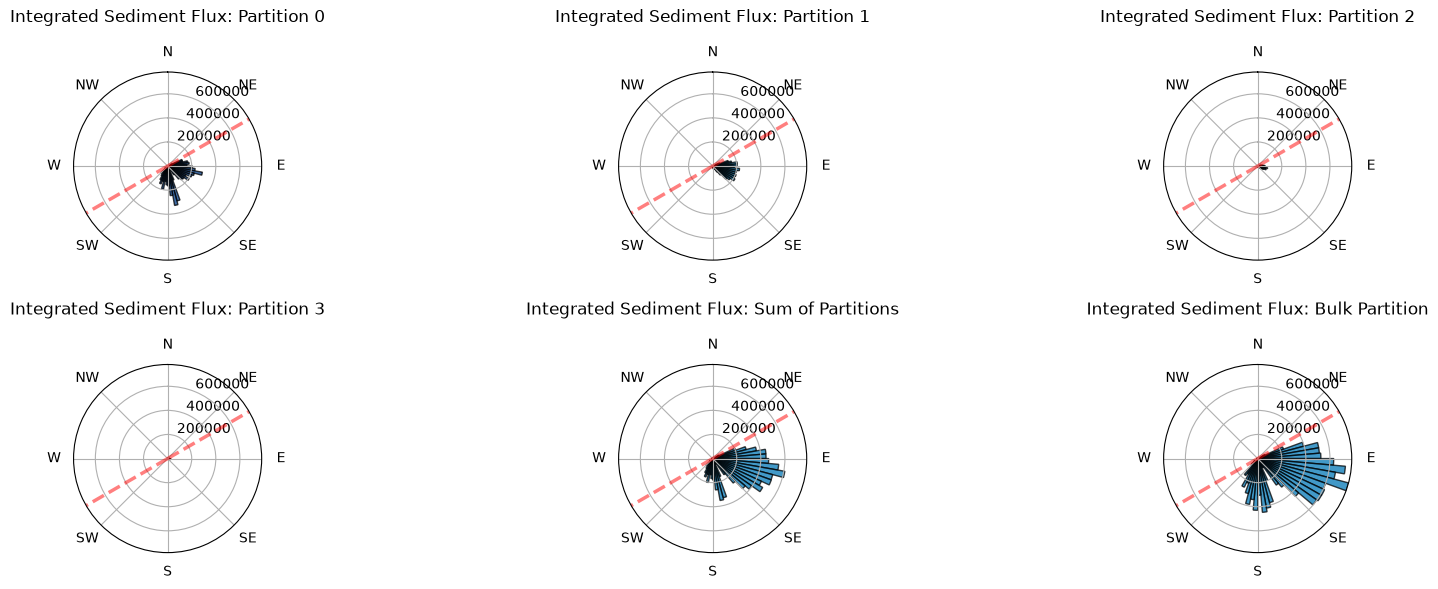

In [14]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

dsE0 = xr.open_dataset('./ncE0_hourly_pertransect.nc')
dsE1 = xr.open_dataset('./ncE1_hourly_pertransect.nc')
dsE2 = xr.open_dataset('./ncE2_hourly_pertransect.nc')
dsE3 = xr.open_dataset('./ncE3_hourly_pertransect.nc')
dsE4 = xr.open_dataset('./ncE4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()
E_snapshot0 = dsE0['E'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()
E_snapshot1 = dsE1['E'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()
E_snapshot2 = dsE2['E'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()
E_snapshot3 = dsE3['E'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()
E_vals0 = E_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])
E_vals0 = np.abs(E_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()
E_vals1 = E_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])
E_vals1 = np.abs(E_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()
E_vals2 = E_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])
E_vals2 = np.abs(E_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()
E_vals3 = E_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])
E_vals3 = np.abs(E_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)


angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)


site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

2964


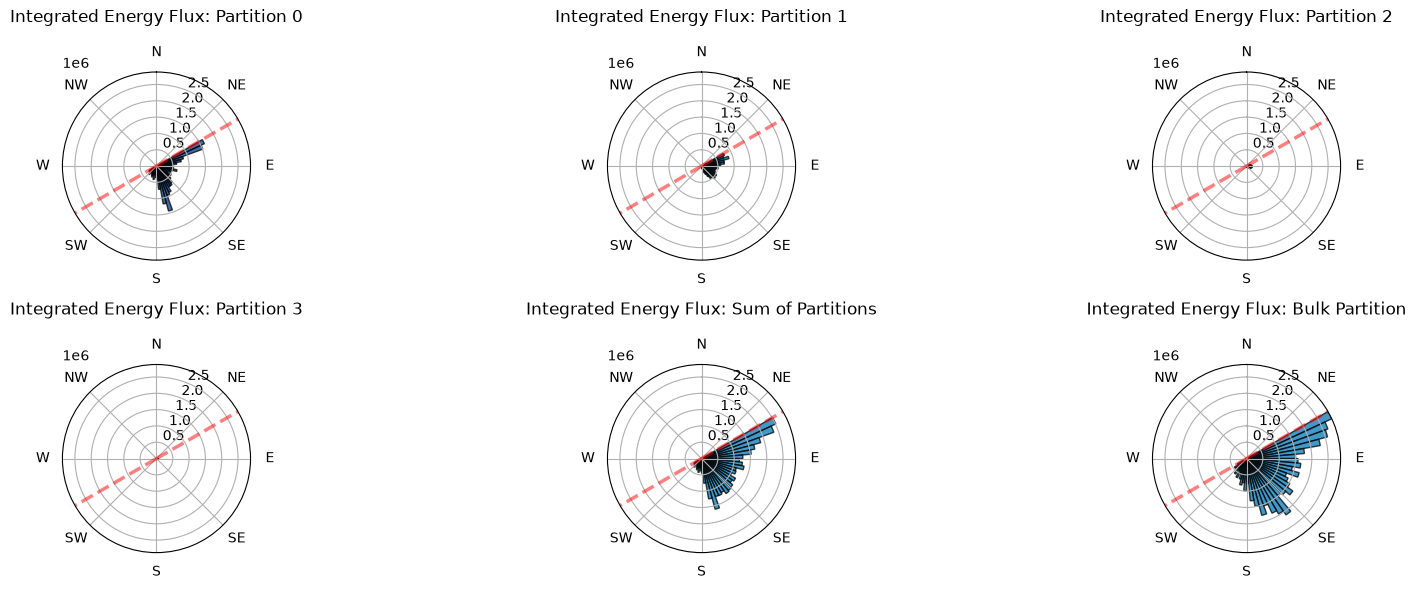

In [15]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

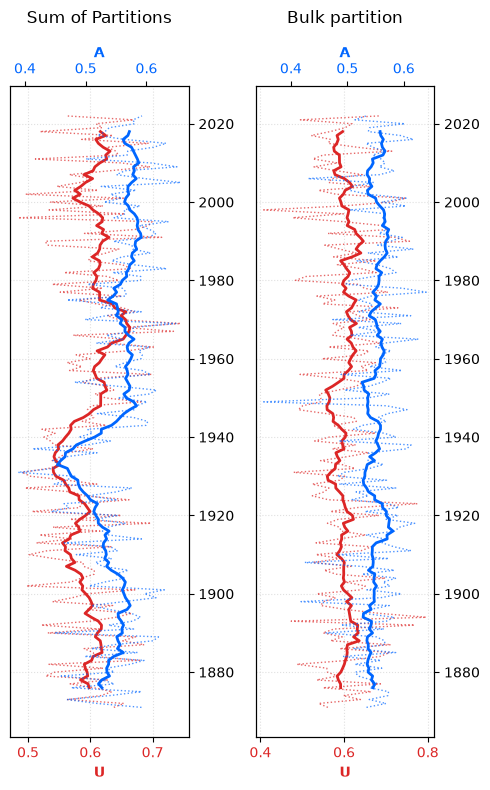

In [16]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

## Site 2

In [17]:
target_site = 1

2963


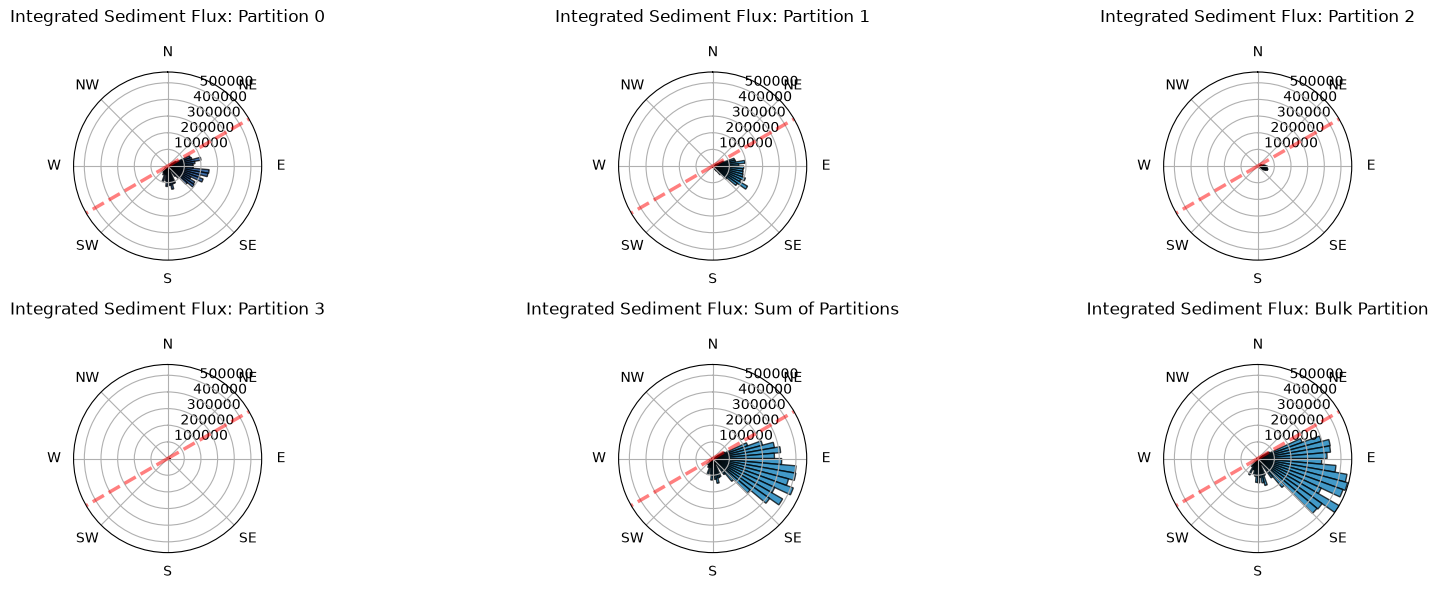

In [18]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

2963


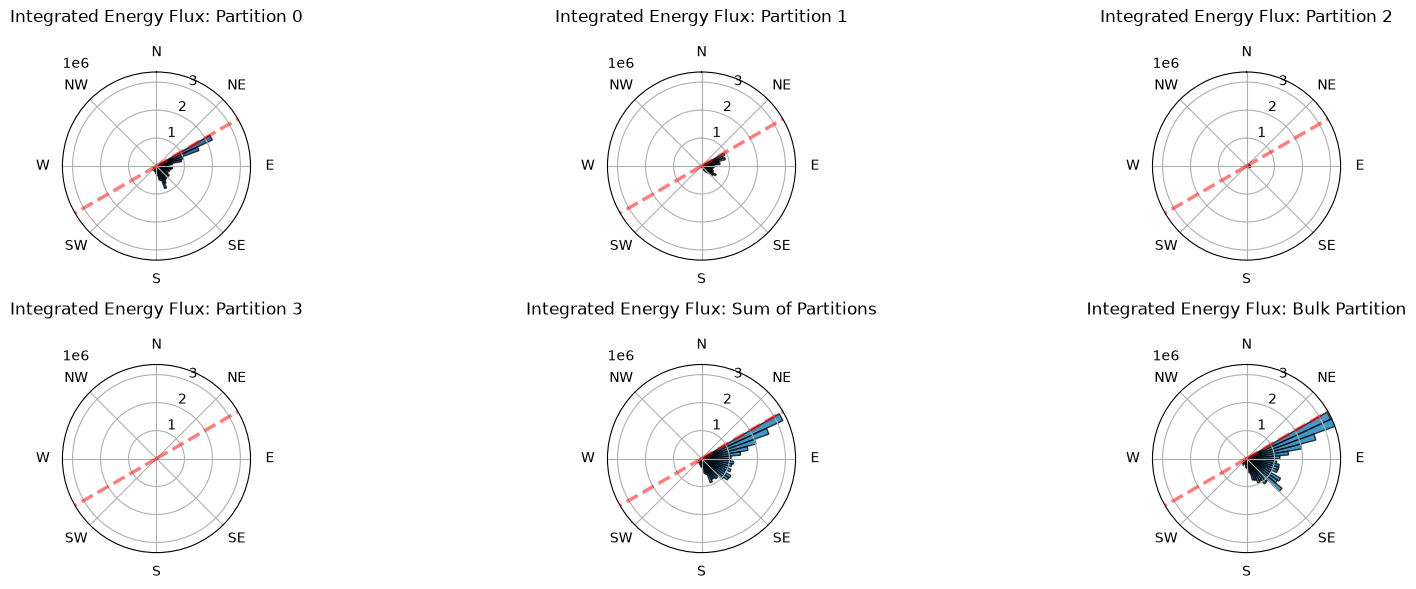

In [19]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

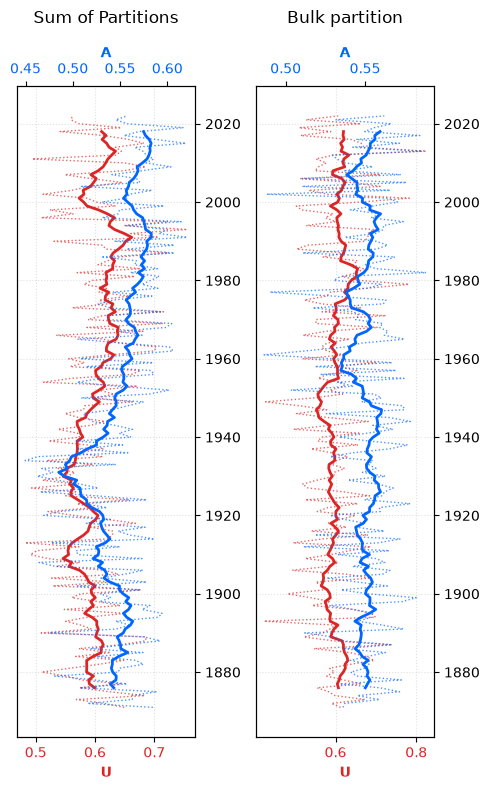

In [20]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

## Site 3

In [21]:
target_site = 2

1670


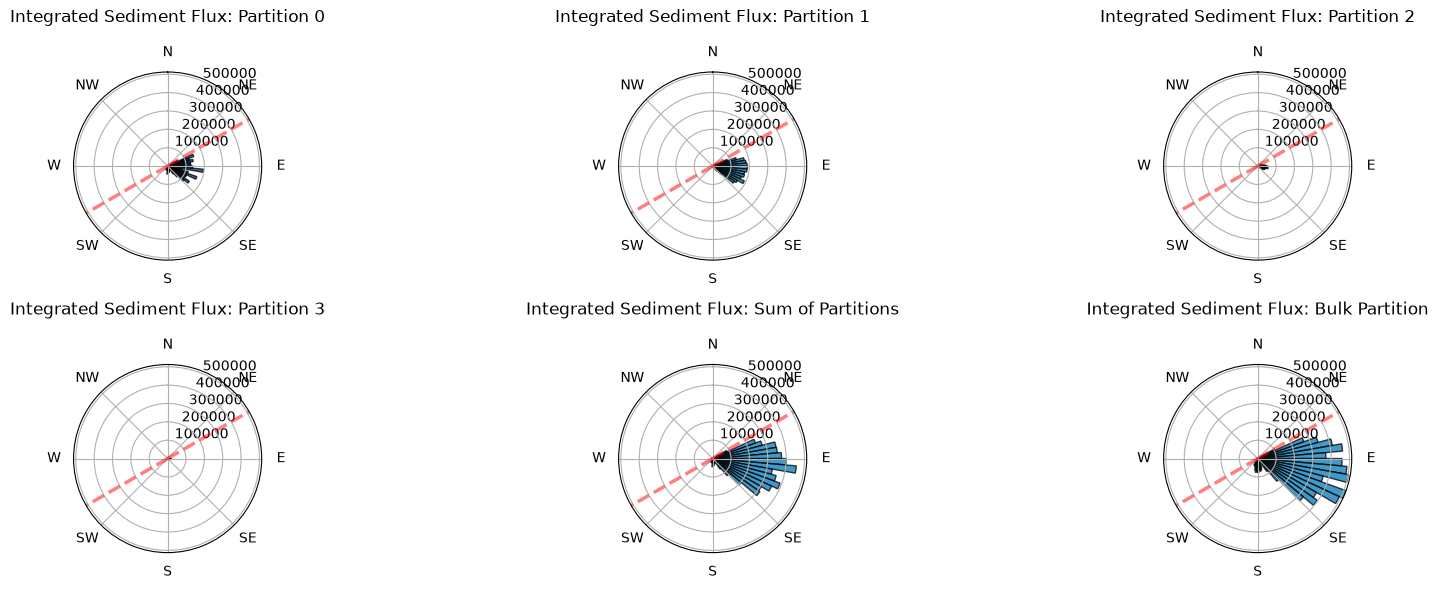

In [22]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)


angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

1670


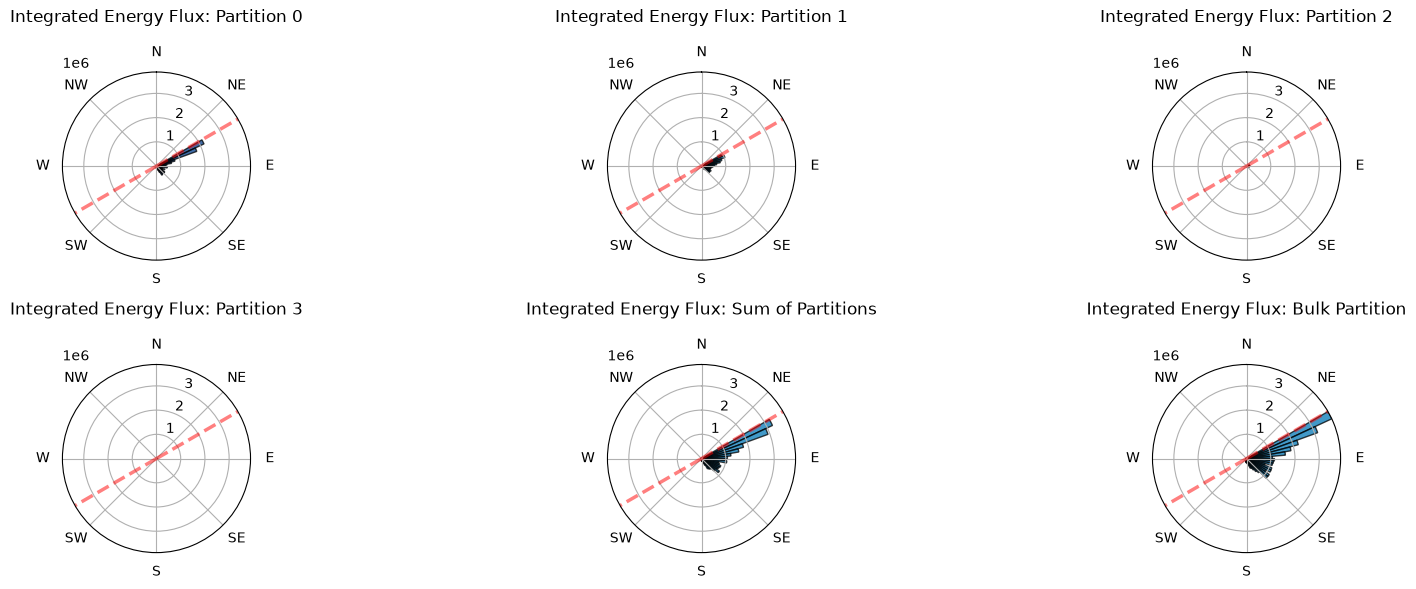

In [23]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

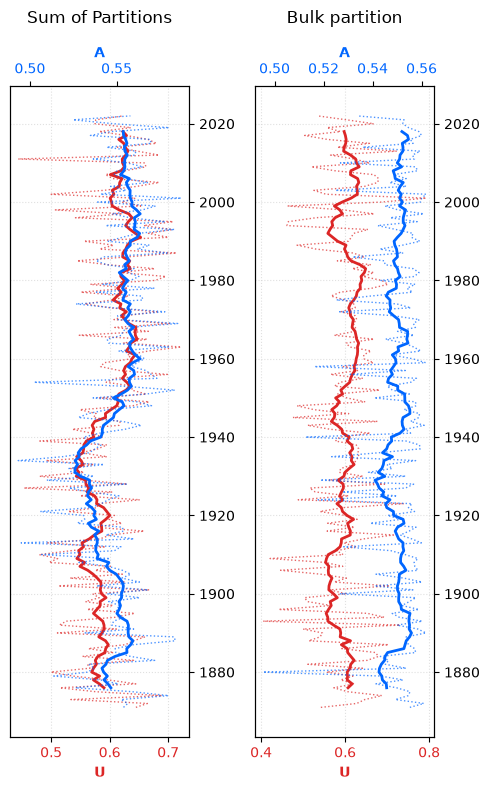

In [24]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

## Site 4

In [25]:
target_site = 3

3124


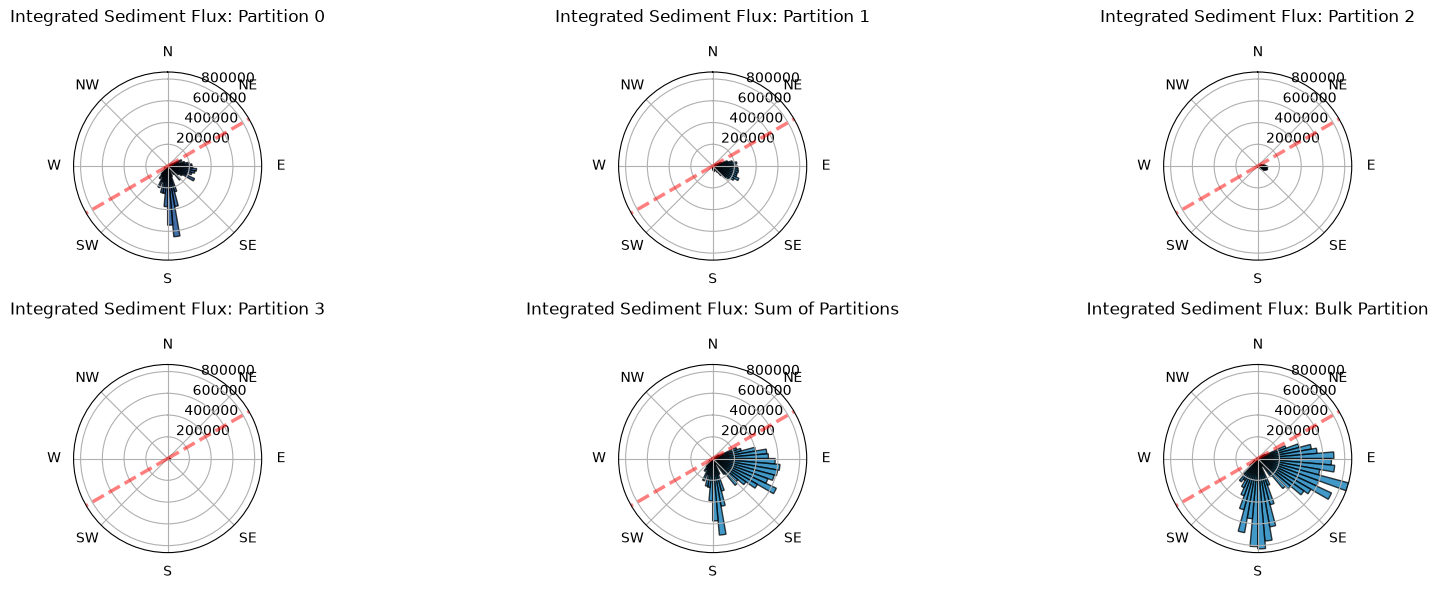

In [26]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)


angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

3124


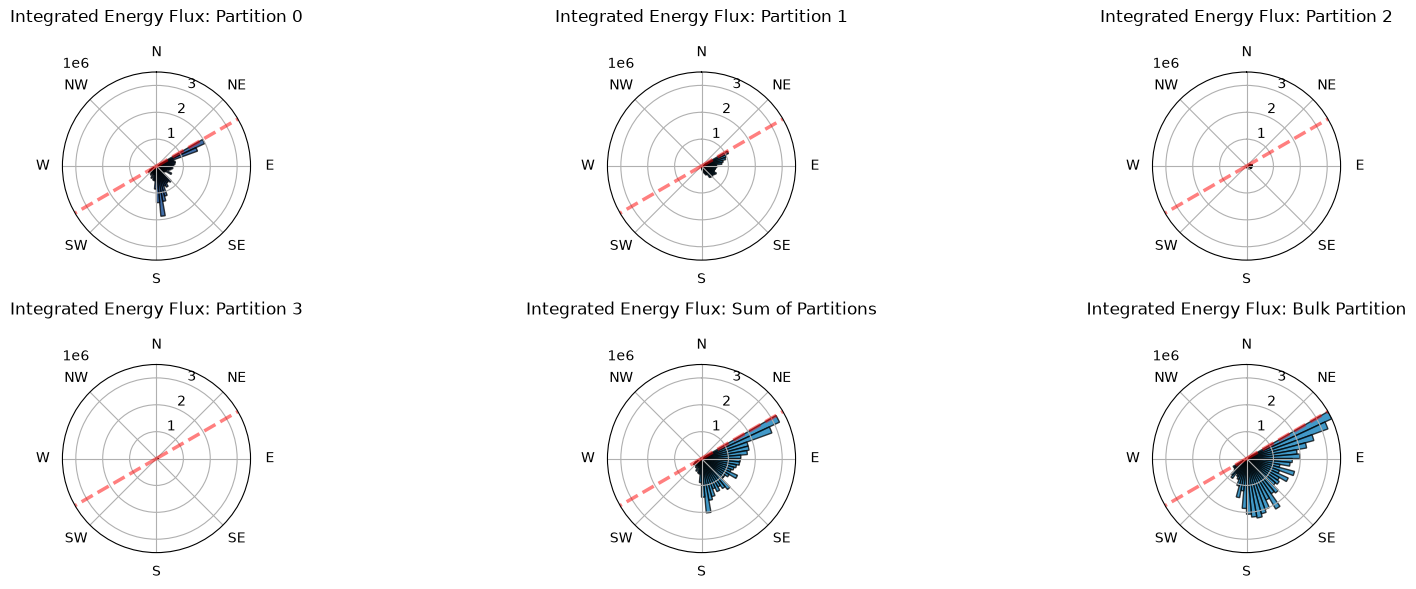

In [27]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

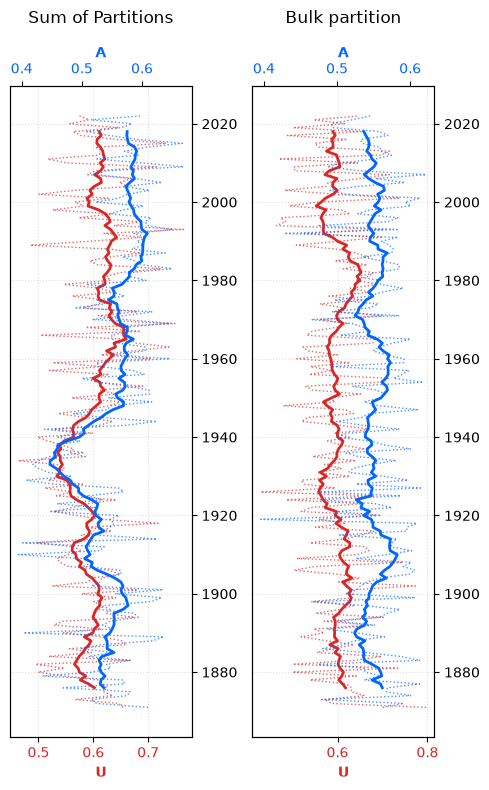

In [28]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

## Site 5

In [29]:
target_site = 4

3096


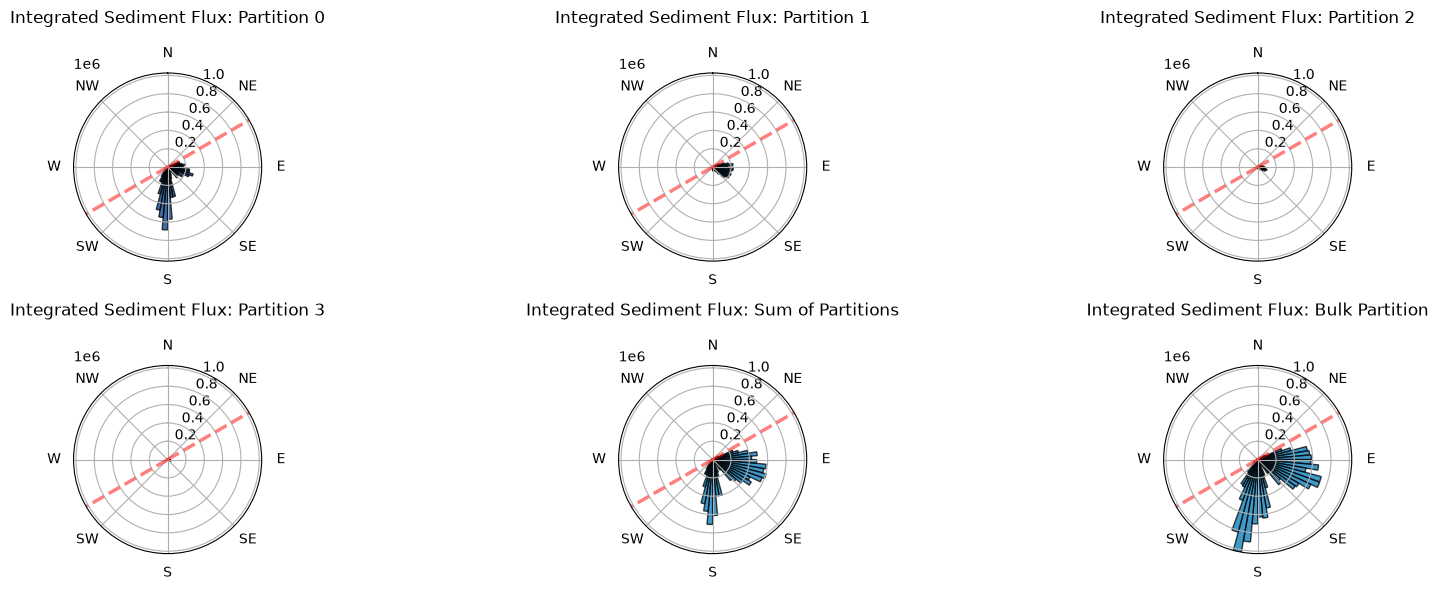

In [30]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)


angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

3096


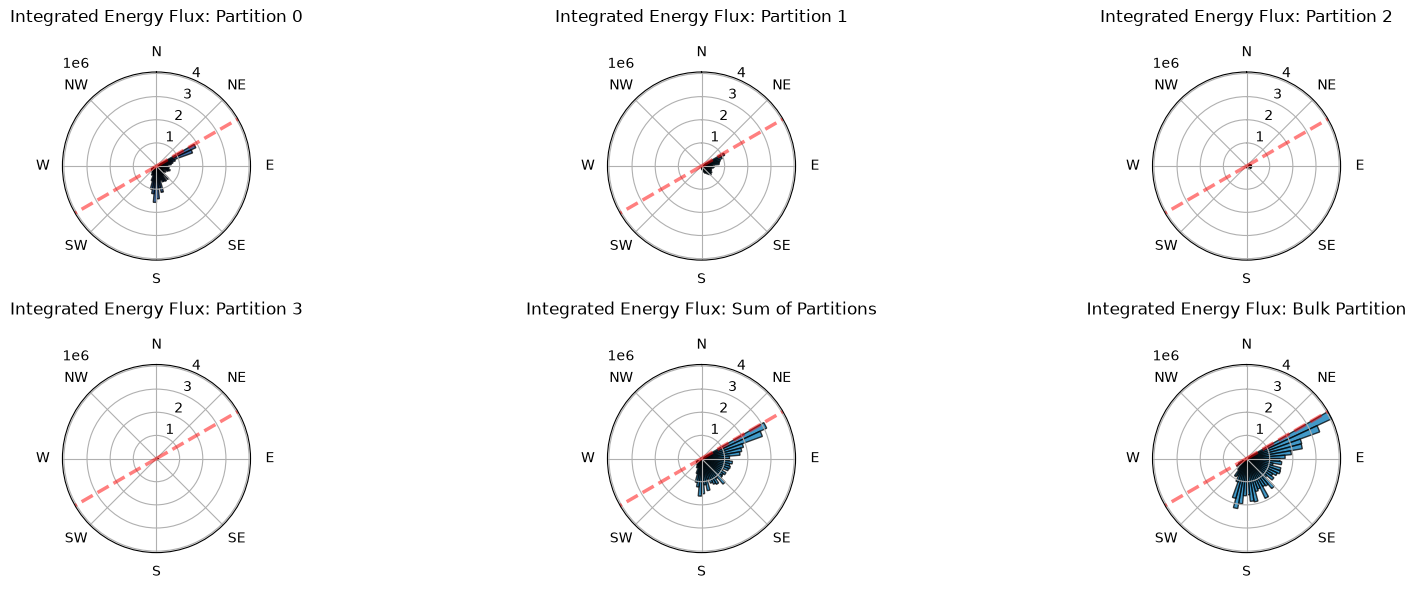

In [31]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

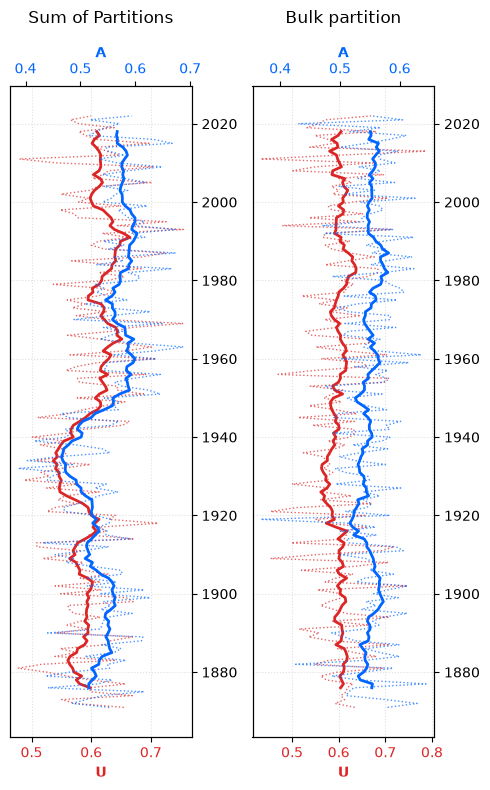

In [32]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

## Site 6

In [33]:
target_site = 5

2844


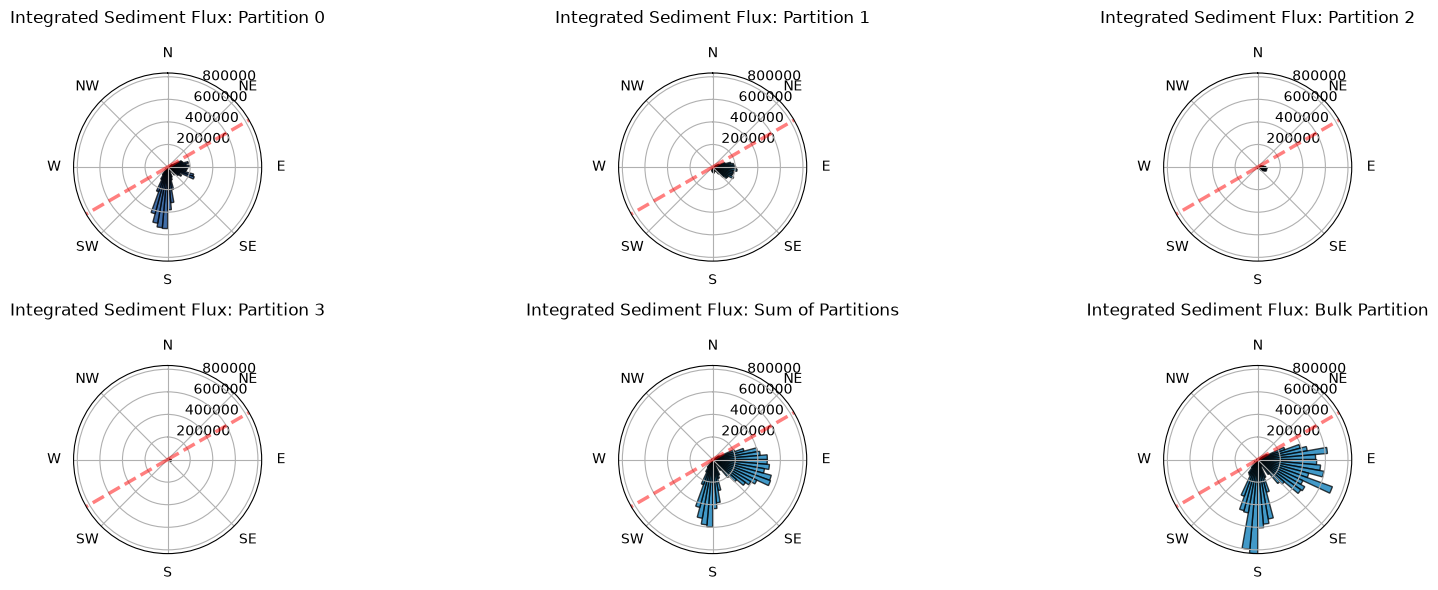

In [34]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)


angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

2844


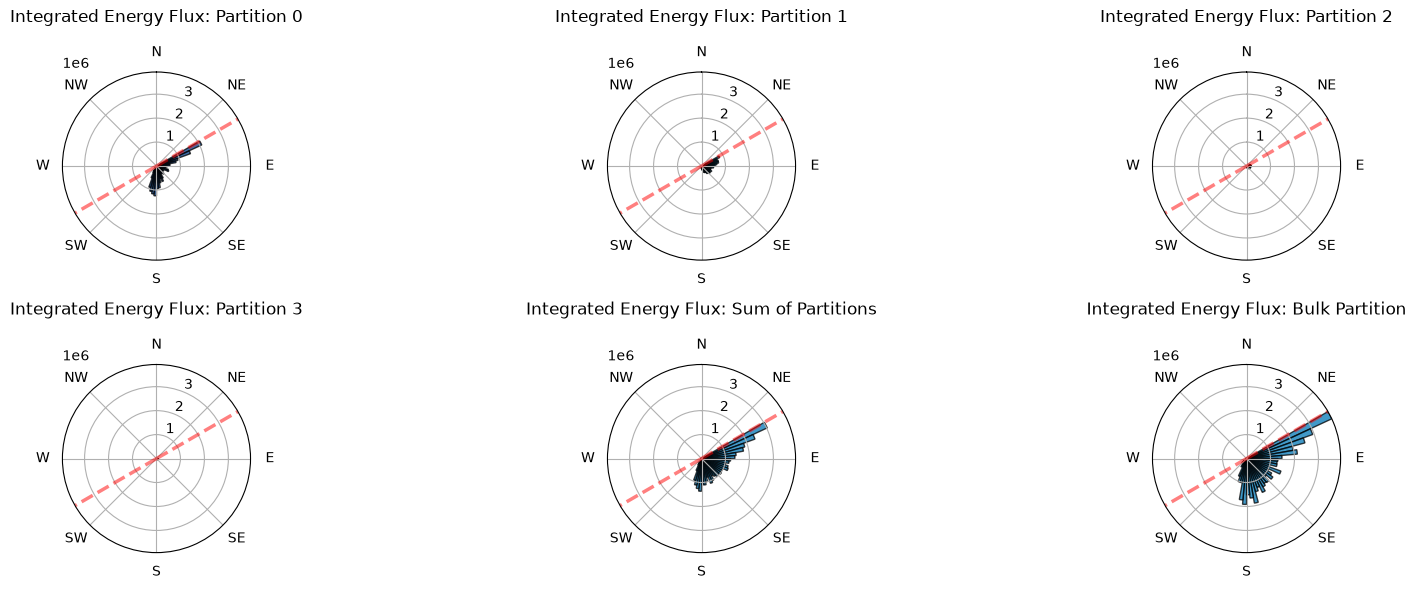

In [35]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

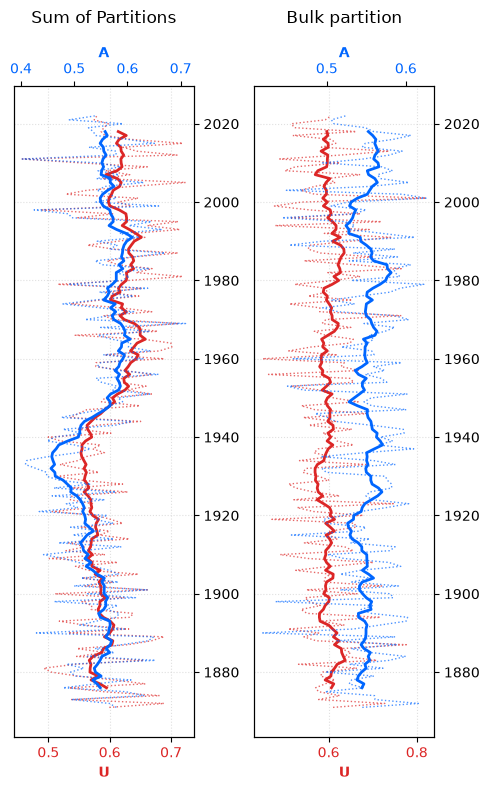

In [36]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

## Site 7

In [37]:
target_site = 6

2776


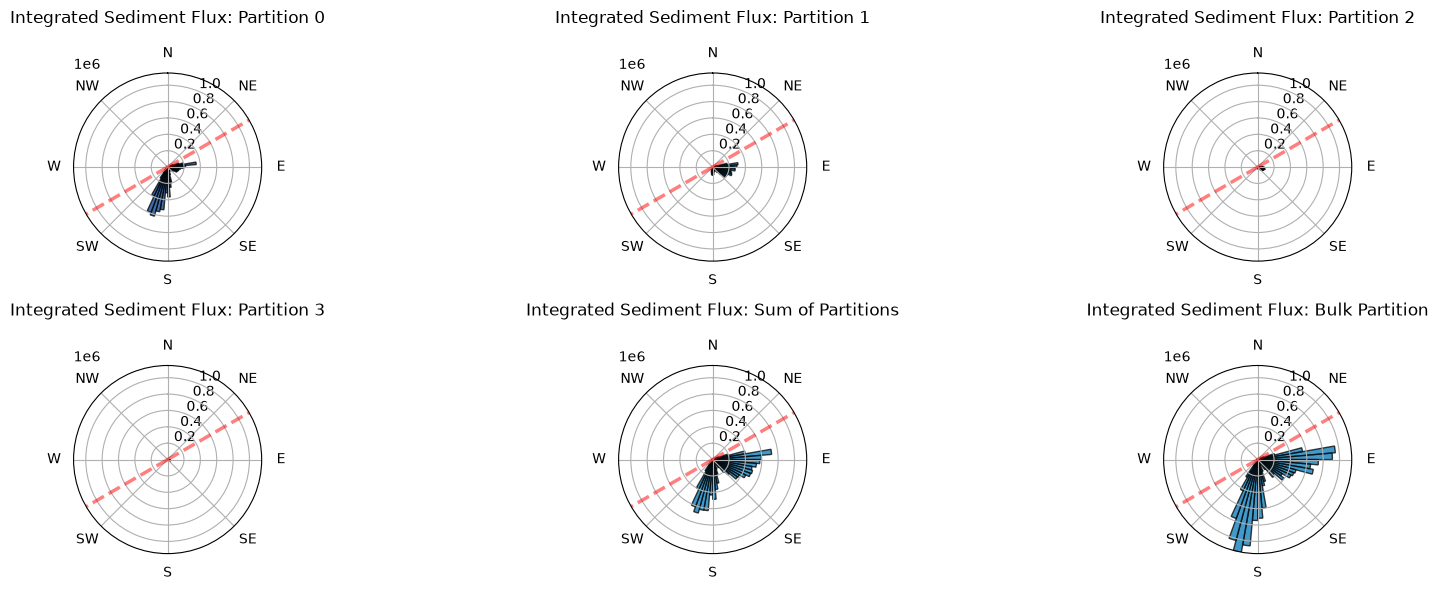

In [38]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)


angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

2776


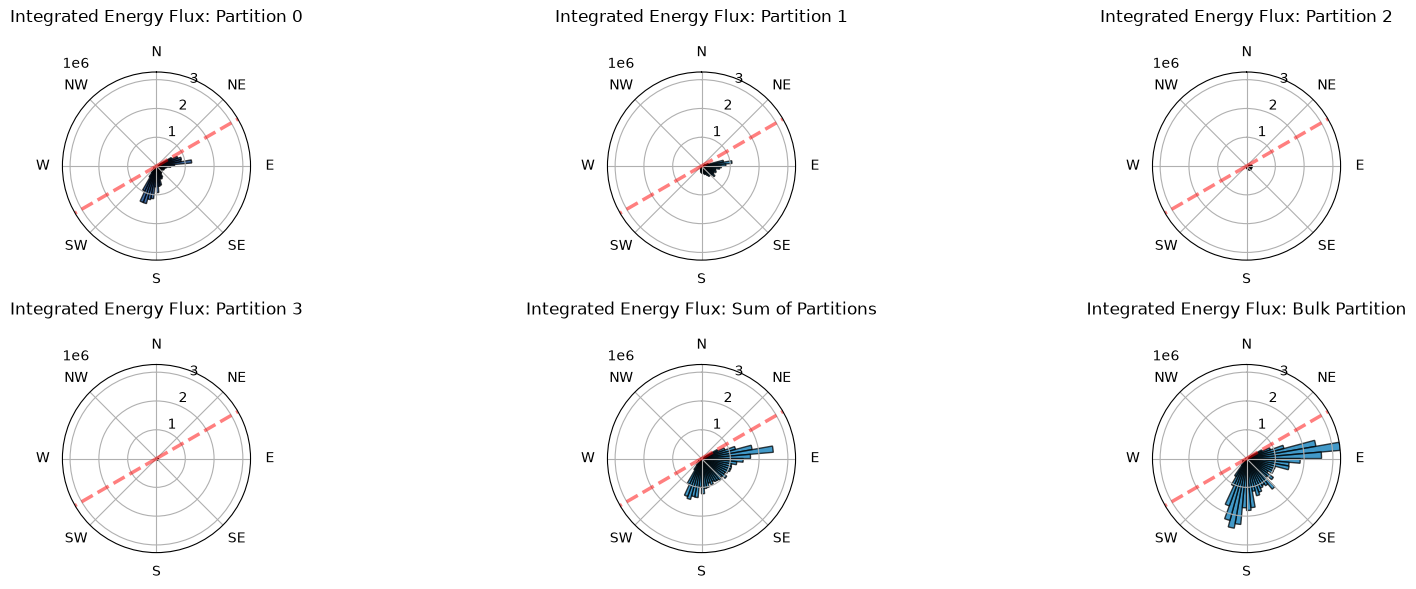

In [39]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

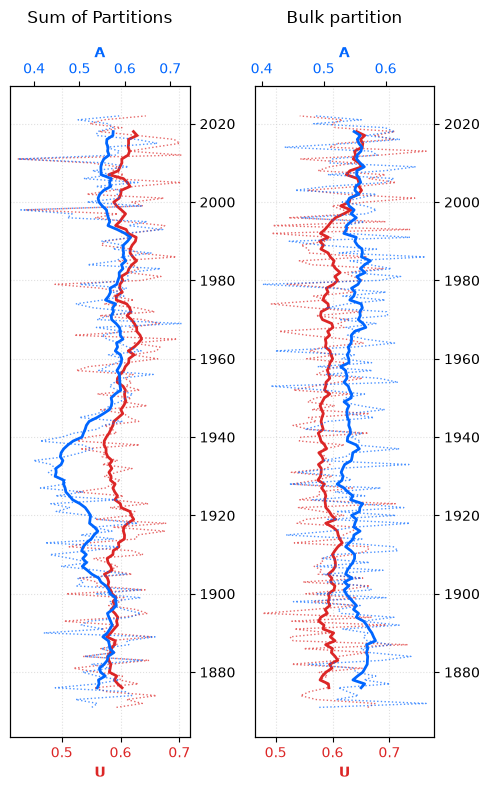

In [40]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

## Site 8

In [41]:
target_site = 7

1517


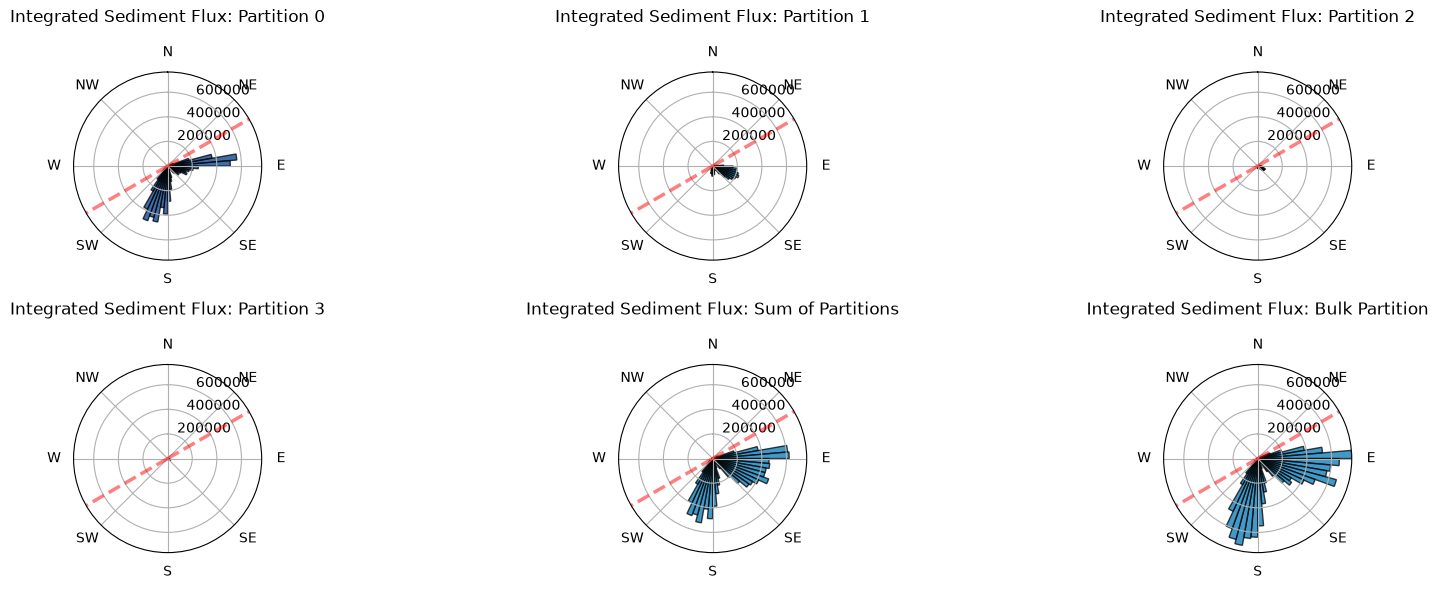

In [42]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)


angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

1517


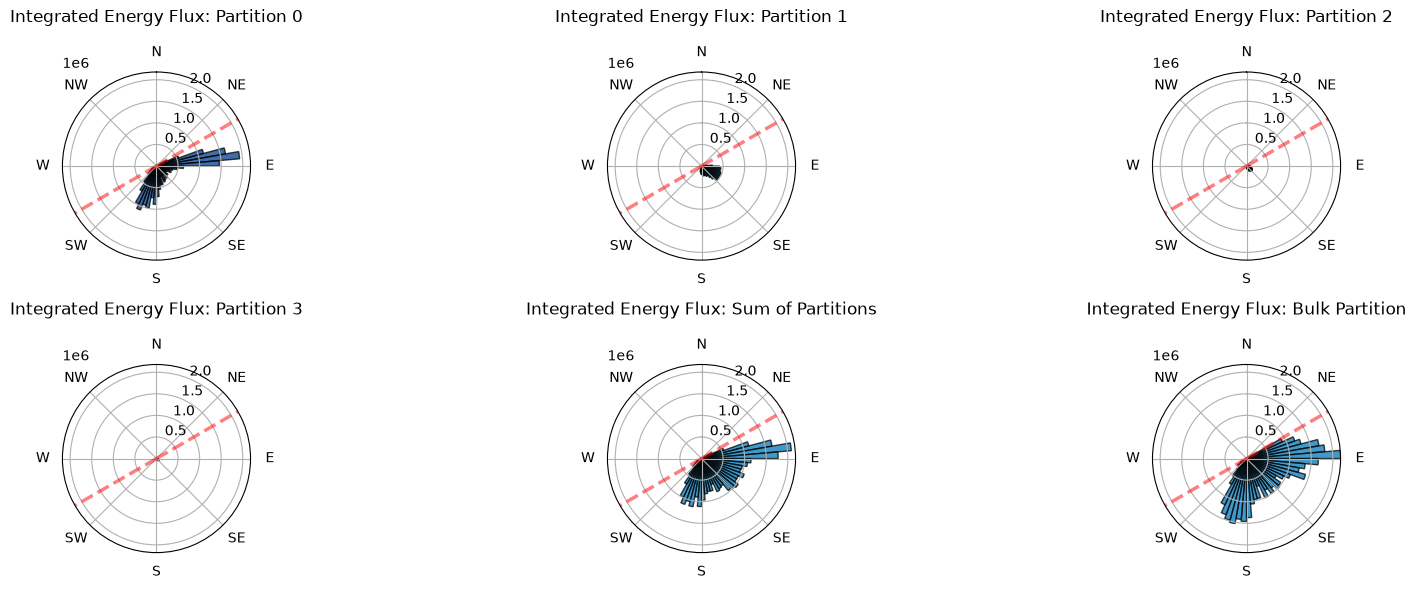

In [43]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

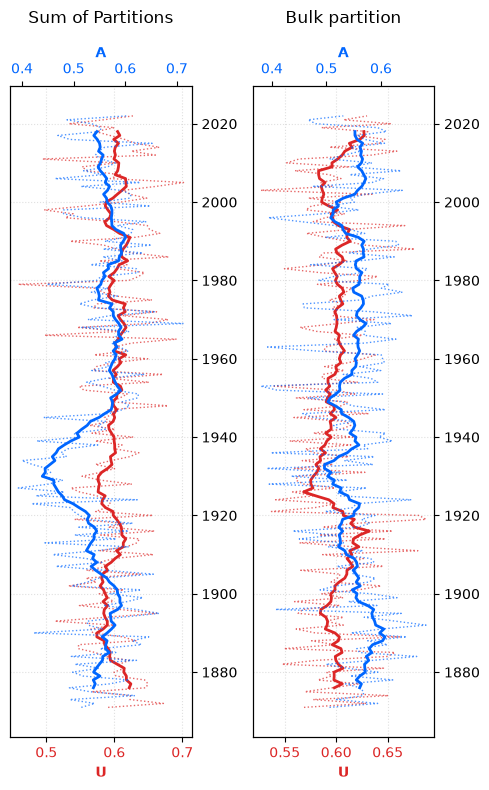

In [44]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

## Site 9

In [45]:
target_site = 8

696


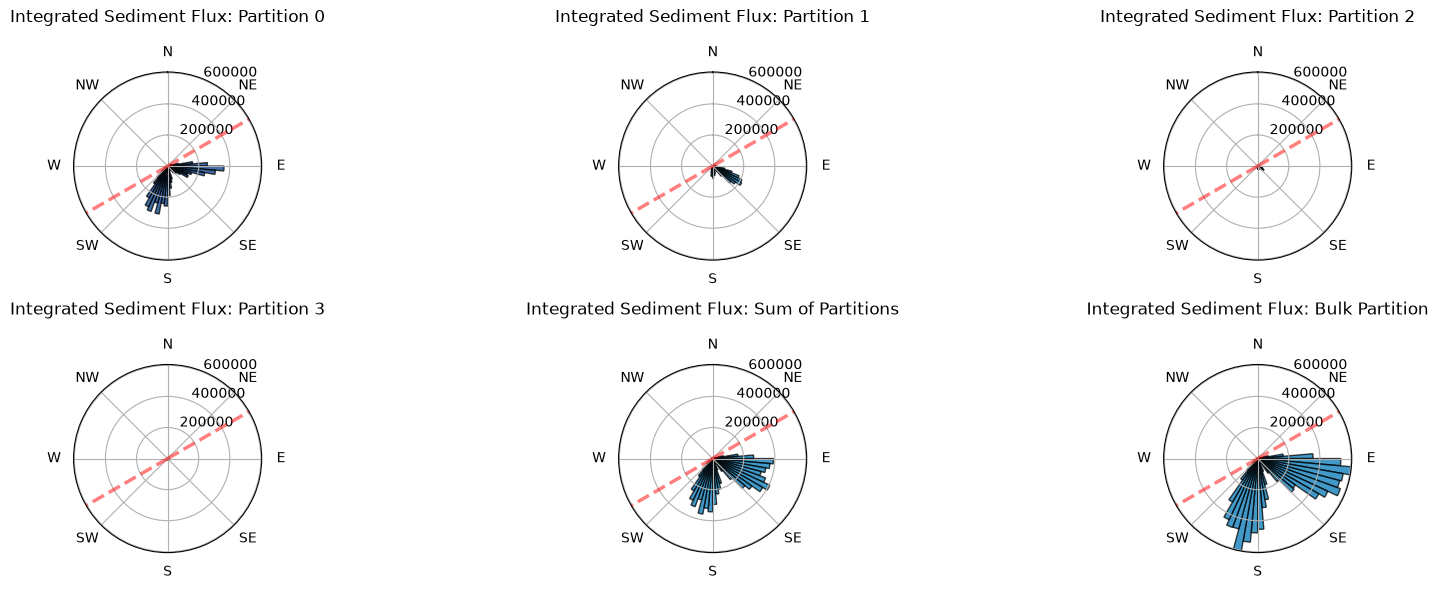

In [46]:
ds0 = xr.open_dataset('./ncqs0_hourly_pertransect.nc')
ds1 = xr.open_dataset('./ncqs1_hourly_pertransect.nc')
ds2 = xr.open_dataset('./ncqs2_hourly_pertransect.nc')
ds3 = xr.open_dataset('./ncqs3_hourly_pertransect.nc')
ds4 = xr.open_dataset('./ncqs4_hourly_pertransect.nc')

wave_lats = dp0.lat.values
wave_lons = dp0.lon.values
transect_lats = ds0.lat.values
transect_lons = ds0.lon.values

qs_snapshot0 = ds0['qs'].isel(site=target_site).squeeze()
dp_snapshot0 = dp0_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot1 = ds1['qs'].isel(site=target_site).squeeze()
dp_snapshot1 = dp1_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot2 = ds2['qs'].isel(site=target_site).squeeze()
dp_snapshot2 = dp2_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot3 = ds3['qs'].isel(site=target_site).squeeze()
dp_snapshot3 = dp3_mapped['dp'].isel(site=target_site).squeeze()

qs_snapshot4 = ds4['qs'].isel(site=target_site).squeeze()
dp_snapshot4 = dp_mapped['dp'].isel(site=target_site).squeeze()

dp_vals0 = dp_snapshot0.values.flatten()
qs_vals0 = qs_snapshot0.values.flatten()

mask = ~np.isnan(dp_vals0) & ~np.isnan(qs_vals0)
dp_vals0 = dp_vals0[mask] % 360
qs_vals0 = np.abs(qs_vals0[mask])

dp_vals1 = dp_snapshot1.values.flatten()
qs_vals1 = qs_snapshot1.values.flatten()

mask = ~np.isnan(dp_vals1) & ~np.isnan(qs_vals1)
dp_vals1 = dp_vals1[mask] % 360
qs_vals1 = np.abs(qs_vals1[mask])

dp_vals2 = dp_snapshot2.values.flatten()
qs_vals2 = qs_snapshot2.values.flatten()

mask = ~np.isnan(dp_vals2) & ~np.isnan(qs_vals2)
dp_vals2 = dp_vals2[mask] % 360
qs_vals2 = np.abs(qs_vals2[mask])

dp_vals3 = dp_snapshot3.values.flatten()
qs_vals3 = qs_snapshot3.values.flatten()

mask = ~np.isnan(dp_vals3) & ~np.isnan(qs_vals3)
dp_vals3 = dp_vals3[mask] % 360
qs_vals3 = np.abs(qs_vals3[mask])

dp_vals4 = dp_snapshot4.values.flatten()
qs_vals4 = qs_snapshot4.values.flatten()

mask = ~np.isnan(dp_vals4) & ~np.isnan(qs_vals4)
dp_vals4 = dp_vals4[mask] % 360
qs_vals4 = np.abs(qs_vals4[mask])

bin_width = 5.0 
bins = np.arange(0, 360 + bin_width, bin_width)
bin_centers = bins[:-1] + (bin_width / 2.0)

bin_indices0 = np.digitize(dp_vals0, bins)
integrated_qs0 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs0[i-1] = np.sum(qs_vals0[bin_indices0 == i])*60*60

bin_indices1 = np.digitize(dp_vals1, bins)
integrated_qs1 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs1[i-1] = np.sum(qs_vals1[bin_indices1 == i])*60*60


bin_indices2 = np.digitize(dp_vals2, bins)
integrated_qs2 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs2[i-1] = np.sum(qs_vals2[bin_indices2 == i])*60*60


bin_indices3 = np.digitize(dp_vals3, bins)
integrated_qs3 = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs3[i-1] = np.sum(qs_vals3[bin_indices3 == i])*60*60
 

dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
qs_vals_combined = np.concatenate([qs_vals0,qs_vals1,qs_vals2,qs_vals3])

bin_indices_combined = np.digitize(dp_vals_combined, bins)
integrated_qs_sum = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_sum[i-1] = np.sum(qs_vals_combined[bin_indices_combined == i])*60*60


bin_indices_4 = np.digitize(dp_vals4, bins)
integrated_qs_bulk = np.zeros(len(bin_centers))

for i in range(1, len(bins)):
    integrated_qs_bulk[i-1] = np.sum(qs_vals4[bin_indices_4 == i])*60*60


angles_rad = np.deg2rad(bin_centers)
width_rad = np.deg2rad(bin_width)

qs_max = qs_max_calc(integrated_qs_sum, integrated_qs_bulk)


angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_qs0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Sediment Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, qs_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_qs1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Sediment Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, qs_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_qs2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Sediment Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, qs_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_qs3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Sediment Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, qs_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_qs_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Sediment Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, qs_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_qs_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Sediment Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, qs_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

696


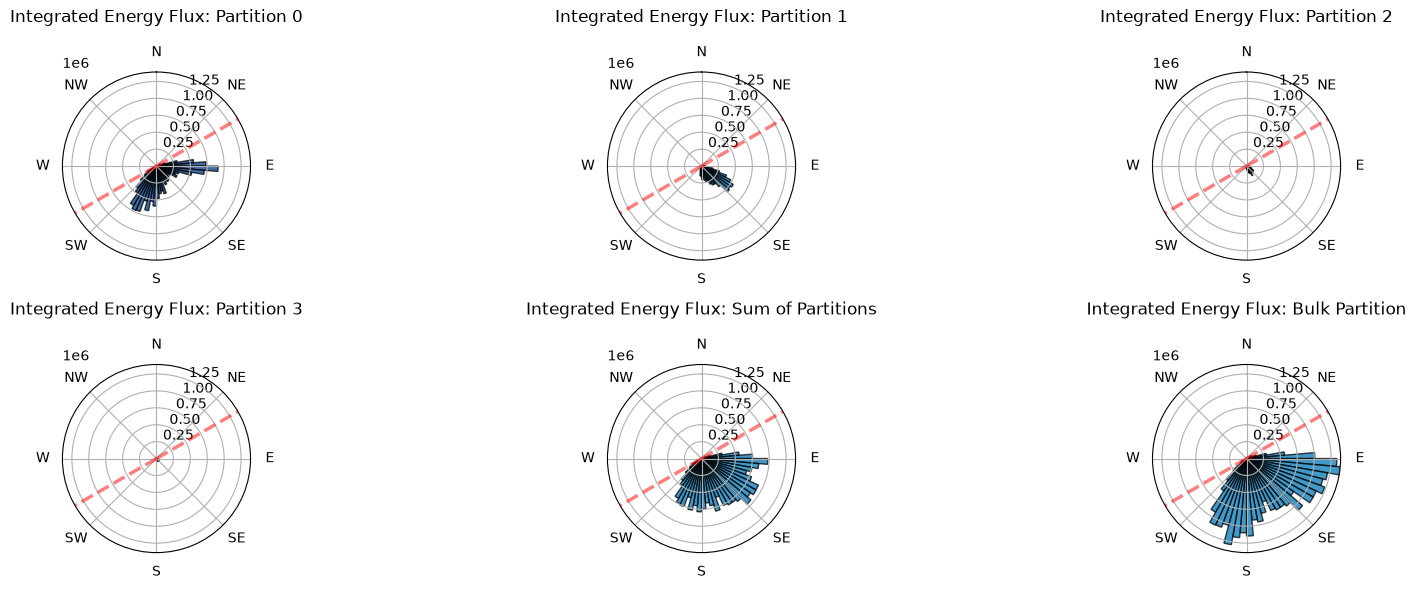

In [47]:
integrated_E0 = u_a_bins(dsE0, dp0_mapped, angles,k,target_site)

integrated_E1 = u_a_bins(dsE1, dp1_mapped, angles,k,target_site)

integrated_E2 = u_a_bins(dsE2, dp2_mapped, angles,k,target_site)

integrated_E3 = u_a_bins(dsE3, dp3_mapped, angles,k,target_site)

# dp_vals_combined = np.concatenate([dp_vals0,dp_vals1,dp_vals2,dp_vals3])
# E_vals_combined = np.concatenate([E_vals0,E_vals1,E_vals2,E_vals3])

# bin_width = 5.0 
# bins = np.arange(0, 360 + bin_width, bin_width)
# bin_centers = bins[:-1] + (bin_width / 2.0)

# bin_indices = np.digitize(dp_vals_combined, bins)
# integrated_E_sum = np.zeros(len(bin_centers))

# for i in range(1, len(bins)):
#     integrated_E_sum[i-1] = np.sum(E_vals_combined[bin_indices == i])*60*60
integrated_E_sum = integrated_E0 + integrated_E1 + integrated_E2 + integrated_E3

integrated_E_bulk = u_a_bins(dsE4, dp_mapped, angles,k,target_site)

E_max = max(integrated_E_sum.max(), integrated_E_bulk.max())

angle = 60
angle0 = (angle+180)%360
angle = np.deg2rad(angle)
angle0 = np.deg2rad(angle0)

fig = plt.figure(figsize=(18, 6))

ax1 = fig.add_subplot(2, 3, 1, projection='polar') 
ax2 = fig.add_subplot(2, 3, 2, projection='polar') 
ax3 = fig.add_subplot(2, 3, 3, projection='polar') 
ax4 = fig.add_subplot(2, 3, 4, projection='polar')

# Plot showing sum of partitions
ax5 = fig.add_subplot(2, 3, 5, projection ='polar')

# Plot for bulk parameters
ax6 = fig.add_subplot(2,3,6, projection = 'polar')

ax = [ax1, ax2, ax3, ax4, ax5,ax6]


bars0 = ax[0].bar(
    angles_rad, 
    integrated_E0, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[0].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[0].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[0].set_theta_zero_location('N') 
ax[0].set_theta_direction(-1)       

ax[0].set_title(f'Integrated Energy Flux: Partition 0', pad=17)
ax[0].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[0].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[0].set_rlim(0, E_max)

bars1 = ax[1].bar(
    angles_rad, 
    integrated_E1, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[1].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[1].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[1].set_theta_zero_location('N') 
ax[1].set_theta_direction(-1)       

ax[1].set_title(f'Integrated Energy Flux: Partition 1', pad=17)
ax[1].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[1].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[1].set_rlim(0, E_max)



bars2 = ax[2].bar(
    angles_rad, 
    integrated_E2, 
    width=width_rad, 
    bottom=0.0, 
    color='#023e8a', 
    edgecolor='black', 
    alpha=0.75
)

ax[2].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[2].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[2].set_theta_zero_location('N') 
ax[2].set_theta_direction(-1)       

ax[2].set_title(f'Integrated Energy Flux: Partition 2', pad=17)
ax[2].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[2].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[2].set_rlim(0, E_max)

bars3 = ax[3].bar(
    angles_rad, 
    integrated_E3, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[3].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[3].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[3].set_theta_zero_location('N') 
ax[3].set_theta_direction(-1)       

ax[3].set_title(f'Integrated Energy Flux: Partition 3', pad=17)
ax[3].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[3].set_rlim(0, E_max)

#Plot showing sum of partitions
bars4 = ax[4].bar(
    angles_rad, 
    integrated_E_sum, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[4].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[4].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[4].set_theta_zero_location('N') 
ax[4].set_theta_direction(-1)       

ax[4].set_title(f'Integrated Energy Flux: Sum of Partitions', pad=17)
ax[4].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[4].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[4].set_rlim(0, E_max)


#Bulk parameter polar plot
bars5 = ax[5].bar(
    angles_rad, 
    integrated_E_bulk, 
    width=width_rad, 
    bottom=0.0, 
    color='#0277b6', 
    edgecolor='black', 
    alpha=0.75
)

ax[5].axvline(x=angle, color='red', linestyle='--', linewidth=2.5, alpha=.5)
ax[5].axvline(x=angle0, color='red', linestyle='--', linewidth=2.5, alpha=.5)

# plot in bearing space
ax[5].set_theta_zero_location('N') 
ax[5].set_theta_direction(-1)       

ax[5].set_title(f'Integrated Energy Flux: Bulk Partition', pad=17)
ax[5].set_xticks(np.linspace(0, 2 * np.pi, 8, endpoint=False))
ax[5].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax[5].set_rlim(0, E_max)

site_num = ds['site'].isel(site= target_site).values

print(site_num)

plt.tight_layout()
plt.show()

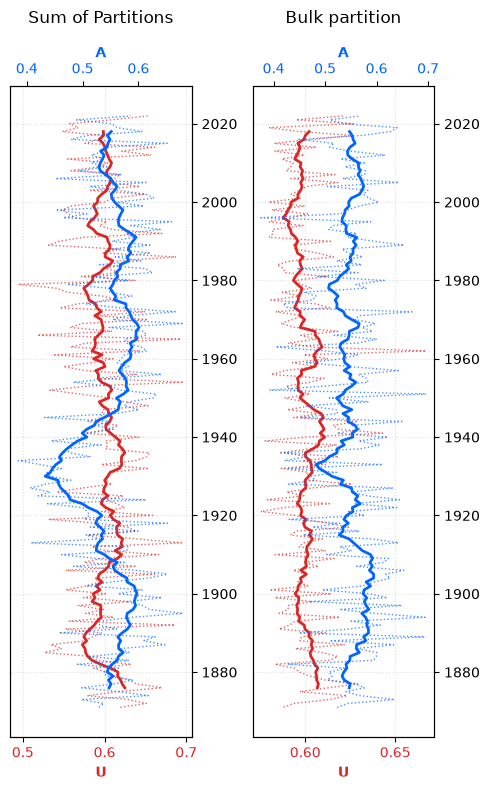

In [48]:
U_sum, A_sum, U_bulk, A_bulk, years = u_a_calc_per_year([dsE0,dsE1,dsE2,dsE3],dsE4,[dp0_mapped,dp1_mapped,dp2_mapped,dp3_mapped],dp_mapped, angles, target_site, U, A)
u_a_plot(U_sum,A_sum,U_bulk,A_bulk,years)

### U and A Data Save (Sites 1-9)

In [57]:
num_sites = len(dsE4['site'])
 
U_sum_all, A_sum_all = [], []
U_bulk_all, A_bulk_all = [], []
 
for site_idx in range(num_sites):
    U_sum_s, A_sum_s, U_bulk_s, A_bulk_s, years = u_a_calc_per_year(
        [dsE0, dsE1, dsE2, dsE3], dsE4,
        [dp0_mapped, dp1_mapped, dp2_mapped, dp3_mapped], dp_mapped,
        angles, site_idx, U, A)
 
    U_sum_all.append(U_sum_s)
    A_sum_all.append(A_sum_s)
    U_bulk_all.append(U_bulk_s)
    A_bulk_all.append(A_bulk_s)
 
start_year = int(dsE4['time'].dt.year[0])
year_values = np.arange(start_year, start_year + years)
 
ds_out = xr.Dataset(
    data_vars={
        'U_sum':  (('time', 'site'), np.stack(U_sum_all, axis=1)),
        'A_sum':  (('time', 'site'), np.stack(A_sum_all, axis=1)),
        'U_bulk': (('time', 'site'), np.stack(U_bulk_all, axis=1)),
        'A_bulk': (('time', 'site'), np.stack(A_bulk_all, axis=1)),
    },
    coords={
        'time': ('time', year_values, {'units': 'year'}),
        'site': dsE4['site'].values,
        'lat': ('site', dsE4['lat'].values),
        'lon': ('site', dsE4['lon'].values),
    },
    attrs={
        'max_angle': max_angle,
        'shoreline_angle': angles,
        'default_U': U,
        'default_A': A,
    },
)

ds_out.to_netcdf('U_A_yearly_per_site.nc')
print(ds_out)

<xarray.Dataset> Size: 45kB
Dimensions:  (time: 152, site: 9)
Coordinates:
  * time     (time) int64 1kB 1871 1872 1873 1874 1875 ... 2019 2020 2021 2022
  * site     (site) <U4 144B '2964' '2963' '1670' '3124' ... '2776' '1517' '696'
    lat      (site) float64 72B 36.4 36.3 36.26 36.19 ... 34.81 34.12 33.38
    lon      (site) float64 72B -75.2 -75.4 -75.59 ... -75.81 -77.0 -78.38
Data variables:
    U_sum    (time, site) float64 11kB 0.6376 0.6493 0.6447 ... 0.6274 0.6535
    A_sum    (time, site) float64 11kB 0.5918 0.5847 0.554 ... 0.6031 0.5868
    U_bulk   (time, site) float64 11kB 0.5612 0.6124 0.5422 ... 0.6299 0.6208
    A_bulk   (time, site) float64 11kB 0.5339 0.5361 0.5552 ... 0.5309 0.5675
Attributes:
    max_angle:        45
    shoreline_angle:  60
    default_U:        0.6
    default_A:        0.55
